# Notebook 05: Advanced Multi-Pollutant Analytics & PM2.5 Time-Series Forecasting
## BDA Mini-Project: Air Pollution Analysis Across India

### Objectives:
- Analyze inter-pollutant Pearson correlations and atmospheric chemistry interactions.
- Implement strict chronological train/validation/test forecasting experiment for Delhi NCR.
- Benchmark Persistence Baseline, Rolling Average, Ridge Regression, and Gradient Boosting.
- Discuss forecasting horizons, meteorological limitations, and academic conclusions.

In [1]:
import sys, os
from pathlib import Path
PROJECT_ROOT = Path(os.getcwd()).resolve()
if PROJECT_ROOT.name == 'notebooks':
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))

import json
import pandas as pd
from IPython.display import Image, display
import src.config as config

corr_df = pd.read_csv(config.OUTPUTS_TABLES_DIR / 'pollutant_correlation_matrix.csv', index_col=0)
print('--- Inter-Pollutant Correlation Matrix ---')
print(corr_df.to_string())

--- Inter-Pollutant Correlation Matrix ---
       PM2.5  PM10  NO2  SO2  CO  O3
PM2.5    NaN   NaN  NaN  NaN NaN NaN
PM10     NaN   NaN  NaN  NaN NaN NaN
NO2      NaN   NaN  NaN  NaN NaN NaN
SO2      NaN   NaN  NaN  NaN NaN NaN
CO       NaN   NaN  NaN  NaN NaN NaN
O3       NaN   NaN  NaN  NaN NaN NaN


### 1. Inter-Pollutant Correlation Heatmap

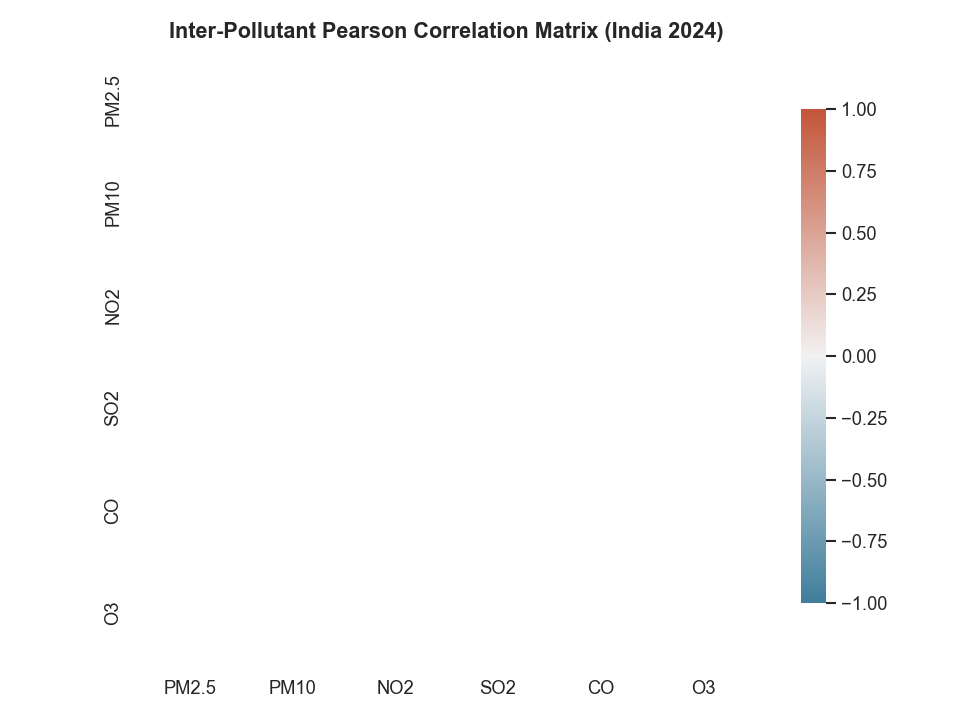

In [2]:
hm_path = PROJECT_ROOT / 'outputs' / 'charts' / '05_pollutant_correlation_heatmap.png'
display(Image(filename=str(hm_path)))

### 2. PM2.5 Forecasting Model Comparison (Winter Holdout Set)

In [3]:
metrics_path = PROJECT_ROOT / 'outputs' / 'metrics' / 'forecasting_metrics.json'
with open(metrics_path) as f:
    fc_res = json.load(f)
df_eval = pd.DataFrame(fc_res).T
print(df_eval.to_string())

                     MAE   RMSE     R2
Persistence_Lag1   15.60  23.59  0.960
Rolling_Mean_24h   55.68  78.93  0.552
Ridge_Regression    9.17  14.65  0.985
Gradient_Boosting  18.04  37.40  0.899


### 3. Actual vs Forecasted PM2.5 Time-Series Evaluation

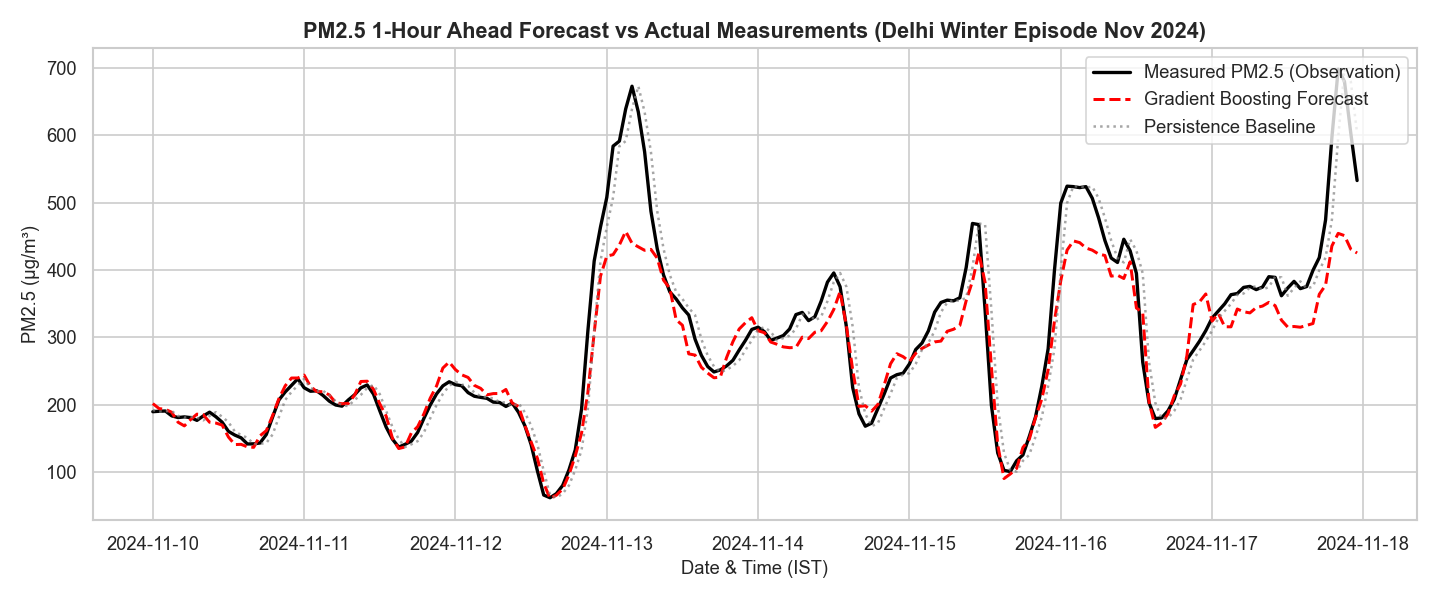

In [4]:
fc_chart = PROJECT_ROOT / 'outputs' / 'charts' / '05_pm25_forecasting_evaluation.png'
display(Image(filename=str(fc_chart)))

### 4. Forecasting Limitations & Conclusions
- **Persistence Strength:** In short 1-hour ahead forecasting, strong auto-correlation ($y_{t-1}$) provides a competitive baseline.
- **Meteorological Dependency:** Multi-day forecasts require numerical weather prediction (wind speed, boundary layer height) to capture abrupt frontal ventilation.